# XGBoost / LightGBM: gradient-boosted trees + TF-IDF

*Data: the feature-engineered file `data/processed/model/model_features.csv`, trained on `split == "train"` with the shared `cv_fold` column, plus one check on the held-out `split == "test"`.*

**Goal:** same as the logistic regression baseline. Predict whether a certificate program meets the Workforce Pell value-added earnings standard, using numeric program/school data plus the text describing its field and related jobs.

**Target:** `vae_positive_local` (1 = locally adjusted 1-year earnings above $23,475, 0 = at or below)

**Score to beat:** LR text + numeric: **F1 0.925 / ROC-AUC 0.947** (team RF/XGBoost baseline reached ROC-AUC 0.961).

## What stays the same as `lr_baseline.ipynb` (so results are comparable)
Steps 1-4 are copied unchanged: same dropped columns, same target and labeled set, same text field, same numeric feature list, same demographics exclusion, same 5-fold `GroupKFold` by `UNITID`, same metrics.

## What changes, and why

| # | Decision | Choice | Why |
|---|---|---|---|
| 1 | Imputing / scaling | **Removed** | XGBoost and LightGBM handle blanks natively and don't care about feature scale. Missingness itself can be informative |
| 2 | TF-IDF size | 500 terms (was 2,000), **dense** output | Trees split on one column at a time, so fewer, stronger terms work better. Dense output avoids an XGBoost gotcha (see note in Step 5) |
| 3 | Class imbalance | `scale_pos_weight = n(class 0) / n(class 1)` | Same effect as `class_weight="balanced"` in the LR. Switch: `BALANCE` |
| 4 | Tuning | `RandomizedSearchCV`, 30 draws per model, scored on ROC-AUC, same grouped folds | Boosting has many more knobs than `C`, so a grid is too slow |
| 5 | Which library | Run **both**, pick the better CV ROC-AUC | No reason to guess |
| 6 | Explanations | SHAP instead of coefficients | The LR notebook recommended this because overlapping features distort coefficients |
| 7 | Honest score | Optional nested CV (`RUN_NESTED`) | Boosting has more tuning freedom, so same-fold tuning is more optimistic than it was for LR |

In [1]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, TargetEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import (PredefinedSplit, GroupKFold, RandomizedSearchCV, cross_validate,
                                     cross_val_predict)
from sklearn.metrics import (roc_auc_score, f1_score, precision_score, recall_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import joblib

DATA_DIR = Path("../../../data/processed/model")      # output of notebooks/modeling/Feature_Engineering.ipynb
OUTPUT_DIR = "../../../models/lgbm_xgboost"
RANDOM_STATE = 42
INCLUDE_DEMOGRAPHICS = False    # set True to include student race/ethnicity shares
BALANCE = True                  # upweight the minority class ("does not meet"), like class_weight="balanced"
TFIDF_MAX_TERMS = 500
N_ITER = 30                     # random-search draws per model; lower for a quick run
RUN_NESTED = False              # True = slower, honest (nested) score for the winning model

dictionary = pd.read_csv(DATA_DIR / "feature_dictionary.csv")
CATEGORICAL = dictionary.loc[dictionary["type"] == "categorical", "feature"].tolist()
df = pd.read_csv(DATA_DIR / "model_features.csv", low_memory=False, dtype={c: str for c in CATEGORICAL})
print("Shape:", df.shape)

Shape: (26678, 151)


In [2]:
# Column drops, leakage removal and categorical clean-up were done in feature engineering
FEATURES = dictionary["feature"].tolist()
print("Features in the dictionary:", len(FEATURES), "| categorical:", CATEGORICAL)

Features in the dictionary: 121 | categorical: ['bea_region', 'cipcode', 'cip_series', 'y1_earnings_natl_benchmark_level', 'iclevel', 'control', 'highest_offering', 'calendar_system', 'price_reporting', 'locale', 'locale_group', 'preddeg']


In [3]:
TARGET = "vae_positive_local"
labeled = df[df["split"] == "train"].copy()      # training rows ("labeled" keeps the name used below)
test = df[df["split"] == "test"].copy()
y = labeled[TARGET].astype(int)
y_test = test[TARGET].astype(int)
groups = labeled["unitid"]

print("Training programs:", len(labeled), "| schools:", groups.nunique())
print("Held-out test programs:", len(test), "| schools:", test["unitid"].nunique())
print(y.value_counts().rename({1: "1 = meets", 0: "0 = does not meet"}).to_string())
print(f"\nAlways guessing 'meets' = {y.mean():.1%} accuracy -> the bar to beat")

# XGBoost/LightGBM equivalent of class_weight="balanced": weight positives by n_neg / n_pos (< 1 here)
SPW = (y == 0).sum() / (y == 1).sum() if BALANCE else 1.0
print(f"scale_pos_weight = {SPW:.3f}")

Training programs: 5619 | schools: 1642
Held-out test programs: 1405 | schools: 437
vae_positive_local
1 = meets            4402
0 = does not meet    1217

Always guessing 'meets' = 78.3% accuracy -> the bar to beat
scale_pos_weight = 0.276


In [4]:
def build_text(frame):
    text = (frame["cipdesc"].fillna("") + " | " + frame["xw_top_occupations"].fillna(""))
    return (text.str.lower()
                .str.replace(r"[^a-z\s]", " ", regex=True)   # keep letters only
                .str.replace(r"\s+", " ", regex=True)
                .str.strip())

df["program_text"] = build_text(df)
labeled["program_text"] = df.loc[labeled.index, "program_text"]
test["program_text"] = df.loc[test.index, "program_text"]

print("Rows with empty text:", (df["program_text"] == "").sum())
print("Unique text values:", df["program_text"].nunique())

Rows with empty text: 0
Unique text values: 360


In [5]:
CAT_LOW = [c for c in CATEGORICAL if c != "cipcode"]   # ordinal codes: trees split on them directly
CIP = ["cipcode"]                                      # 360 values: target encoding (cross-fitted)
NUMERIC_FEATURES = [c for c in FEATURES if c not in CATEGORICAL]
DEMOGRAPHICS = ["ugds_white", "ugds_black", "ugds_hisp", "ugds_asian", "ugds_aian", "ugds_nhpi", "ugds_2mor"]
if INCLUDE_DEMOGRAPHICS:
    NUMERIC_FEATURES += DEMOGRAPHICS

print("Numeric features:", len(NUMERIC_FEATURES))
print("Categorical:", len(CAT_LOW), "ordinal-encoded +", CIP, "target-encoded")
print("Demographics included:", INCLUDE_DEMOGRAPHICS)

Numeric features: 109
Categorical: 11 ordinal-encoded + ['cipcode'] target-encoded
Demographics included: False


In [6]:
def make_estimator(name):
    # n_jobs=1 here because the search / CV below parallelize across folds instead
    if name == "xgb":
        return XGBClassifier(tree_method="hist", scale_pos_weight=SPW, eval_metric="logloss",
                             random_state=RANDOM_STATE, n_jobs=1)
    if name == "lgbm":
        return LGBMClassifier(scale_pos_weight=SPW, subsample_freq=1,
                              random_state=RANDOM_STATE, n_jobs=1, verbose=-1)
    raise ValueError(name)

def make_gbm_pipeline(name, use_text=True, use_numeric=True, params=None):
    parts = []
    if use_text:
        parts.append(("text", TfidfVectorizer(ngram_range=(1, 2), min_df=5, stop_words="english",
                                               sublinear_tf=True, max_features=TFIDF_MAX_TERMS), "program_text"))
    if use_numeric:
        parts.append(("num", "passthrough", NUMERIC_FEATURES))
        parts.append(("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                            encoded_missing_value=-1), CAT_LOW))
        parts.append(("cip", TargetEncoder(random_state=RANDOM_STATE), CIP))
    pre = ColumnTransformer(parts, remainder="drop", sparse_threshold=0)
    pipe = Pipeline([("prep", pre), ("clf", make_estimator(name))])
    if params:
        pipe.set_params(**params)
    return pipe

INPUT_COLS = ["program_text"] + NUMERIC_FEATURES + CAT_LOW + CIP
X = labeled[INPUT_COLS]
X_test = test[INPUT_COLS]
cv = PredefinedSplit(labeled["cv_fold"])      # shared 5 folds, grouped by school
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

PARAM_DIST = {
    "xgb": {
        "clf__n_estimators":     [200, 400, 800],
        "clf__learning_rate":    [0.02, 0.05, 0.1],
        "clf__max_depth":        [3, 4, 6, 8],
        "clf__min_child_weight": [1, 3, 5, 10],
        "clf__subsample":        [0.7, 0.85, 1.0],
        "clf__colsample_bytree": [0.5, 0.7, 0.9],
        "clf__reg_lambda":       [1, 5, 10],
    },
    "lgbm": {
        "clf__n_estimators":      [200, 400, 800],
        "clf__learning_rate":     [0.02, 0.05, 0.1],
        "clf__num_leaves":        [15, 31, 63],
        "clf__max_depth":         [-1, 4, 6],
        "clf__min_child_samples": [10, 20, 40],
        "clf__subsample":         [0.7, 0.85, 1.0],
        "clf__colsample_bytree":  [0.5, 0.7, 0.9],
        "clf__reg_lambda":        [0, 1, 5, 10],
    },
}
print("Pipelines ready.")

Pipelines ready.


In [7]:
best_params, tuning_rows = {}, []
for name in ["xgb", "lgbm"]:
    rs = RandomizedSearchCV(make_gbm_pipeline(name), PARAM_DIST[name], n_iter=N_ITER, cv=cv,
                            scoring="roc_auc", n_jobs=-1, random_state=RANDOM_STATE)
    rs.fit(X, y, groups=groups)
    best_params[name] = rs.best_params_
    tuning_rows.append({"model": name, "best CV ROC-AUC": round(rs.best_score_, 4),
                        "std at best": round(rs.cv_results_["std_test_score"][rs.best_index_], 4)})
    print(name, rs.best_params_)

pd.DataFrame(tuning_rows)

xgb {'clf__subsample': 0.85, 'clf__reg_lambda': 5, 'clf__n_estimators': 400, 'clf__min_child_weight': 1, 'clf__max_depth': 8, 'clf__learning_rate': 0.05, 'clf__colsample_bytree': 0.5}
lgbm {'clf__subsample': 0.85, 'clf__reg_lambda': 10, 'clf__num_leaves': 63, 'clf__n_estimators': 400, 'clf__min_child_samples': 10, 'clf__max_depth': 6, 'clf__learning_rate': 0.1, 'clf__colsample_bytree': 0.7}


,model,best CV ROC-AUC,std at best
0,xgb,0.9520,0.0089
1,lgbm,0.9521,0.0093


In [8]:
variants = {
    "Always 'meets' (dummy)":          None,
    "XGBoost - numeric only":          ("xgb",  False),
    "XGBoost - text + numeric":        ("xgb",  True),
    "LightGBM - numeric only":         ("lgbm", False),
    "LightGBM - text + numeric":       ("lgbm", True),
}

results, raw = {}, {}
for label, spec in variants.items():
    model = DummyClassifier(strategy="most_frequent") if spec is None else \
            make_gbm_pipeline(spec[0], use_text=spec[1], params=best_params[spec[0]])
    s = cross_validate(model, X, y, cv=cv, groups=groups, scoring=scoring, n_jobs=5)
    raw[label] = {m: s["test_" + m].mean() for m in scoring}
    results[label] = {m: f"{s['test_' + m].mean():.3f} ± {s['test_' + m].std():.3f}" for m in scoring}

results["LR text + numeric (baseline notebook)"] = {"accuracy": "0.888", "precision": "0.959", "recall": "0.896",
                                                    "f1": "0.926", "roc_auc": "0.942"}
results_df = pd.DataFrame(results).T
display(results_df)

gbm_labels = [l for l, spec in variants.items() if spec is not None]
BEST_LABEL = max(gbm_labels, key=lambda l: raw[l]["roc_auc"])
BEST_NAME, BEST_USE_TEXT = variants[BEST_LABEL]
print("Best by CV ROC-AUC:", BEST_LABEL)

,accuracy,precision,recall,f1,roc_auc
Always 'meets' (dummy),0.783 ± 0.000,0.783 ± 0.000,1.000 ± 0.000,0.879 ± 0.000,0.500 ± 0.000
XGBoost - numeric only,0.918 ± 0.010,0.949 ± 0.009,0.946 ± 0.010,0.948 ± 0.006,0.952 ± 0.010
XGBoost - text + numeric,0.918 ± 0.008,0.950 ± 0.011,0.945 ± 0.008,0.947 ± 0.005,0.952 ± 0.009
LightGBM - numeric only,0.918 ± 0.009,0.949 ± 0.008,0.946 ± 0.011,0.948 ± 0.006,0.951 ± 0.008
LightGBM - text + numeric,0.920 ± 0.010,0.950 ± 0.008,0.948 ± 0.013,0.949 ± 0.007,0.952 ± 0.009
LR text + numeric (baseline notebook),0.888,0.959,0.896,0.926,0.942


Best by CV ROC-AUC: LightGBM - text + numeric


## Decision: LightGBM, numeric features only

**Choice:** LightGBM trained on the engineered features only (numeric + categorical, no TF-IDF text).

**Why boosted trees over logistic regression**
All four boosted-tree variants beat the LR baseline on the headline metrics (5-fold school-grouped CV on the training rows):

| Model | F1 | ROC-AUC | Recall |
|---|---|---|---|
| LR text + numeric (baseline) | 0.926 | 0.942 | 0.896 |
| LightGBM numeric only | 0.948 | 0.951 | 0.946 |

The biggest gain is recall: the LR missed about 10% of programs that meet the earnings standard, and the boosted trees miss about 5%. Precision is slightly lower (0.959 vs. 0.949), within fold-to-fold variation.

**Why numeric only instead of text + numeric**
Adding the TF-IDF text (field name + related job titles) didn't meaningfully improve any metric for either library: all four variants scored ROC-AUC 0.951–0.952 and F1 0.947–0.949, within the fold-to-fold spread (±0.009). The engineered features already describe the field (`cipcode` target encoding, field-level earnings benchmarks, `expected_vae_field`), so the text is redundant. When scores are tied, we prefer the simpler model: no text preprocessing, no 500 extra columns, and easier to explain.

**Why LightGBM instead of XGBoost**
The two libraries were tied (tuned CV ROC-AUC 0.9521 for LightGBM vs. 0.9520 for XGBoost). We chose LightGBM because it trains faster.

**Caveats**
- The ranking among the four variants is within noise; "Best by CV ROC-AUC" in Step 7 (LightGBM text + numeric) is a tiebreak, not evidence that text helps.
- Hyperparameters were tuned on the same folds used for scoring, so CV scores are slightly optimistic. The held-out test set gives the honest estimate.
- The numeric-only model reuses the hyperparameters tuned on text + numeric.

In [9]:
BEST_NAME, BEST_USE_TEXT = "lgbm", False
BEST_LABEL = "LightGBM - numeric only"

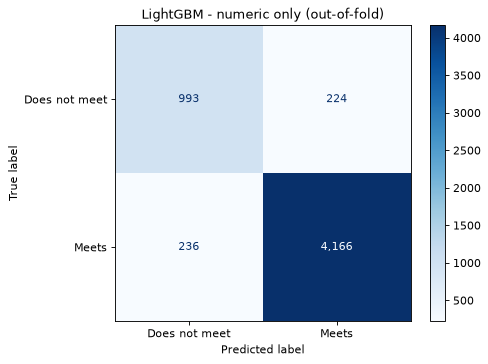

False positives (predicted meets, doesn't): 224
False negatives (predicted doesn't, meets): 236


,threshold,precision,recall,F1,false pos,false neg
0,0.3,0.933,0.966,0.949,303,151
1,0.4,0.942,0.958,0.950,260,184
2,0.5,0.949,0.946,0.948,224,236
3,0.6,0.954,0.932,0.943,197,301
4,0.7,0.961,0.917,0.938,163,367


In [10]:
final_model = make_gbm_pipeline(BEST_NAME, use_text=BEST_USE_TEXT, params=best_params[BEST_NAME])
oof_prob = cross_val_predict(final_model, X, y, cv=cv, groups=groups, method="predict_proba", n_jobs=5)[:, 1]
oof_pred = (oof_prob >= 0.5).astype(int)

cm = confusion_matrix(y, oof_pred)
ConfusionMatrixDisplay(cm, display_labels=["Does not meet", "Meets"]).plot(cmap="Blues", values_format=",")
plt.title(f"{BEST_LABEL} (out-of-fold)")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"False positives (predicted meets, doesn't): {fp:,}")
print(f"False negatives (predicted doesn't, meets): {fn:,}")

rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (oof_prob >= t).astype(int)
    rows.append({"threshold": t, "precision": precision_score(y, p), "recall": recall_score(y, p),
                 "F1": f1_score(y, p), "false pos": int(((p == 1) & (y == 0)).sum()),
                 "false neg": int(((p == 0) & (y == 1)).sum())})
pd.DataFrame(rows).round(3)

false pos- failing programs getting through

false neg- good programs missed

If funding a program that doesn’t pay off is the worse outcome, use a higher cutoff such as 0.6 or 0.7.

If overlooking good programs is the worse outcome, use a lower one such as 0.3 or 0.4.

If you have no strong preference, 0.5 is a reasonable default, and it’s what the rest of the notebook uses.

In [11]:
if RUN_NESTED:
    outer, inner = cv, GroupKFold(n_splits=3)
    nested_auc = []
    for tr, te in outer.split(X, y, groups):
        rs = RandomizedSearchCV(make_gbm_pipeline(BEST_NAME, use_text=BEST_USE_TEXT), PARAM_DIST[BEST_NAME],
                                n_iter=N_ITER, cv=inner, scoring="roc_auc", n_jobs=-1, random_state=RANDOM_STATE)
        rs.fit(X.iloc[tr], y.iloc[tr], groups=groups.iloc[tr])
        nested_auc.append(roc_auc_score(y.iloc[te], rs.predict_proba(X.iloc[te])[:, 1]))
    print(f"Nested ROC-AUC: {np.mean(nested_auc):.3f} ± {np.std(nested_auc):.3f}   (tuned-on-same-folds: {raw[BEST_LABEL]['roc_auc']:.3f})")
else:
    print("Skipped (RUN_NESTED = False)")

Skipped (RUN_NESTED = False)


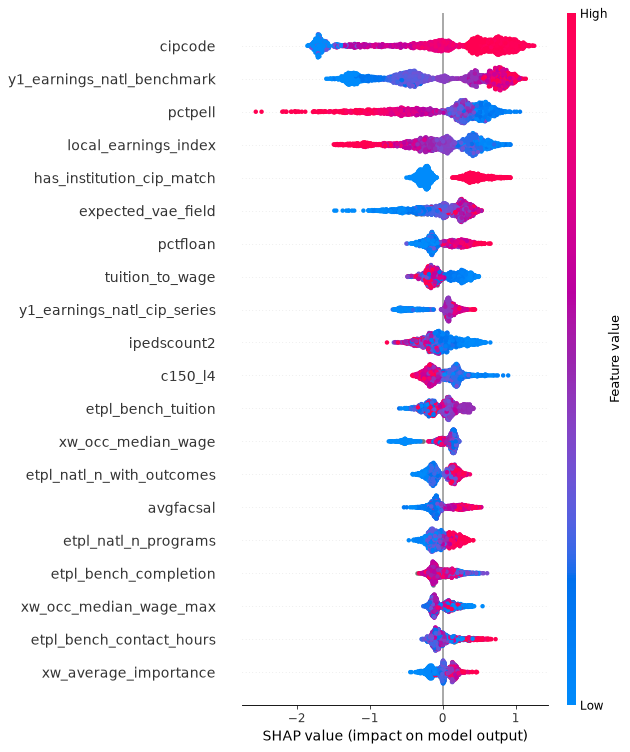

In [12]:
final_model.fit(X, y)
prep, clf = final_model.named_steps["prep"], final_model.named_steps["clf"]
feature_names = [n.replace("num__", "").replace("cat__", "").replace("cip__", "").replace("text__", "text: ")
                 for n in prep.get_feature_names_out()]

try:
    import shap
    Xt = prep.transform(X)
    sample = np.random.RandomState(RANDOM_STATE).choice(len(Xt), size=min(2000, len(Xt)), replace=False)
    sv = shap.TreeExplainer(clf).shap_values(Xt[sample])
    if isinstance(sv, list):          # older shap + LightGBM returns one array per class
        sv = sv[1]
    shap.summary_plot(sv, Xt[sample], feature_names=feature_names, max_display=20)
except ImportError:
    print("shap not installed; showing built-in importances instead")
    imp = pd.Series(clf.feature_importances_, index=feature_names).sort_values(ascending=False).head(20)
    imp[::-1].plot.barh(figsize=(7, 6), title="Feature importance (split-based)")
    plt.tight_layout(); plt.show()

**Notes:**

The plot shows the top 20 features for the final LightGBM model (numeric + categorical, no text), using a random sample of 2,000 training programs. Each dot is one program. Dots to the right push that program's prediction toward "meets," and dots to the left push toward "does not meet." Color shows the feature's value (red = high, blue = low). Features are ranked by average impact.

**Main drivers:**
- **`cipcode` (1st) and `y1_earnings_natl_benchmark` (2nd):** the field of study dominates. `cipcode` is target-encoded (each field's pass rate in the training folds), so fields where most programs pass push strongly toward "meets." Field-level national earnings point the same way.
- **`expected_vae_field`, `y1_earnings_natl_cip_series`, `pctfloan`, `avgfacsal`:** higher values push toward "meets," which is plausible.

**Signals that come from how the label is built (not discoveries):**
- **`local_earnings_index` (4th):** higher values push toward "does not meet." The label divides earnings by this index, so a higher index lowers adjusted earnings by design.

**Signals to read with caution:**
- **`pctpell` (3rd):** a higher Pell share pushes toward "does not meet." This reflects students' circumstances as much as program quality, so it is a fairness concern (see the fairness check).
- **`c150_l4` (completion rate):** higher values push toward "does not meet," the opposite of what we'd expect. This is likely a confounder (for example, short programs with high completion but low earnings). The plot shows what the model learned, not a causal effect.
- **`has_institution_cip_match` (5th) and `ipedscount2`:** both have clear effects but likely reflect data coverage (whether PSEO lists the program, program size) more than program quality.
- **`tuition_to_wage`:** higher tuition relative to the field's wages pushes toward "does not meet," which fits the value-for-money idea behind Workforce Pell.

**Compared with the LR coefficients:** the top drivers and their directions match (field earnings up; local earnings index and Pell share down).

**Caveats:**
- SHAP describes how the model behaves, not what causes earnings.
- When features overlap (field-level benchmarks, `cipcode`, `expected_vae_field`), SHAP splits credit between them, so no single bar should be read too literally.
- Because the label is built from earnings, field-level features ranking first is expected.

In [13]:
rows = []
for grp, idx in labeled.groupby("control").groups.items():
    pos = labeled.index.get_indexer(idx)
    yt, yp, pp = y.loc[idx], oof_pred[pos], oof_prob[pos]
    rows.append({"control": grp, "programs": len(idx), "actual pass rate": yt.mean(), "predicted pass rate": yp.mean(),
                 "precision": precision_score(yt, yp, zero_division=0), "recall": recall_score(yt, yp, zero_division=0),
                 "F1": f1_score(yt, yp, zero_division=0),
                 "ROC-AUC": roc_auc_score(yt, pp) if yt.nunique() > 1 else np.nan})
pd.DataFrame(rows).round(3)

,control,programs,actual pass rate,predicted pass rate,precision,recall,F1,ROC-AUC
0,Private for-profit,2225,0.574,0.551,0.910,0.875,0.892,0.944
1,Private non-profit,226,0.743,0.774,0.869,0.905,0.886,0.878
2,Public,3168,0.933,0.943,0.970,0.980,0.975,0.903


In [14]:
# Held-out test set: the final model (fit on all training rows) scored once on the shared test programs,
# which come from schools never used in training or tuning.
test_prob = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= 0.5).astype(int)
test_results = pd.Series({"accuracy": accuracy_score(y_test, test_pred), "precision": precision_score(y_test, test_pred),
                          "recall": recall_score(y_test, test_pred), "f1": f1_score(y_test, test_pred),
                          "roc_auc": roc_auc_score(y_test, test_prob)}, name=f"{BEST_LABEL} (held-out test)")
print(f"Test programs: {len(y_test):,} | pass rate {y_test.mean():.1%}")
print(confusion_matrix(y_test, test_pred))
test_results.round(3).to_frame()

Test programs: 1,405 | pass rate 78.4%
[[ 268   36]
 [  58 1043]]


,LightGBM - numeric only (held-out test)
accuracy,0.933
precision,0.967
recall,0.947
f1,0.957
roc_auc,0.971


In [15]:
os.makedirs(OUTPUT_DIR, exist_ok=True)

df["p_vae_gbm"] = final_model.predict_proba(df[INPUT_COLS])[:, 1]
df.loc[labeled.index, "p_vae_oof"] = oof_prob

out = df[["unitid", "instnm", "state", "cipcode", "cipdesc", "control", "split",
          "vae_positive_local", "earnings_1yr_local_adj", "p_vae_gbm", "p_vae_oof"]]
out.to_csv(f"{OUTPUT_DIR}/lgbm_predictions.csv", index=False)
joblib.dump(final_model, f"{OUTPUT_DIR}/lgbm_model.joblib")
results_df.to_csv(f"{OUTPUT_DIR}/lgbm_cv_results.csv")
test_results.to_frame().T.to_csv(f"{OUTPUT_DIR}/lgbm_test_results.csv")
with open(f"{OUTPUT_DIR}/best_params.json", "w") as f:
    json.dump({"best_variant": BEST_LABEL, "params": best_params}, f, indent=2, default=str)

print("Saved predictions:", out.shape)
print("Saved model, CV and test results and best params to:", OUTPUT_DIR)

Saved predictions: (26678, 11)
Saved model, CV and test results and best params to: ../../../models/lgbm_xgboost


## Conclusion

*Rerun on the feature-engineered data with the shared train/test split and CV folds.*

**Final model:** LightGBM on the engineered numeric + categorical features (no TF-IDF text). It trains faster than XGBoost, and the two performed the same.

**Performance (5-fold CV on the 5,619 training programs, folds grouped by school):**

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Always guess "meets" (dummy) | 0.783 | 0.783 | 1.000 | 0.879 | 0.500 |
| LR text + numeric (baseline) | 0.888 | 0.959 | 0.896 | 0.926 | 0.942 |
| **LightGBM numeric only** | **0.918** | 0.949 | **0.946** | **0.948** | **0.951** |

**Held-out test set (1,405 programs from 437 schools never used in training):** accuracy **0.933**, precision **0.967**, recall **0.947**, F1 **0.957**, ROC-AUC **0.971** (36 false positives, 58 false negatives). Use these numbers to compare models.

- **Boosted trees beat the LR baseline** on accuracy, recall, F1 and ROC-AUC. Precision is slightly lower, both in CV (0.949 vs. 0.959) and on the test set (0.967 vs. 0.974): the LR baseline is more cautious about saying "meets."
- **The biggest gain is recall:** the LR missed about 10% of programs that meet the standard, and LightGBM misses about 5%.
- **Text did not help.** All four variants scored ROC-AUC 0.951–0.952; the engineered field features already carry what the text says.
- **XGBoost and LightGBM were tied** (tuned CV ROC-AUC 0.9520 vs. 0.9521), so we chose on training speed.

**Errors (out-of-fold, threshold 0.5):** 5,159 of 5,619 training programs correct (91.8%, vs. 88.8% for the LR).
- **False positives: 224.** About 18% of failing programs slip through (LR: 170, 14%).
- **False negatives: 236,** down from 459 for the LR. Good programs overlooked roughly halved.
- **A "does not meet" prediction is right 81% of the time** (993 of 1,229), up from 70% for the LR. It should still prompt review, not automatic rejection.
- **Threshold:** raising the cutoff from 0.5 to 0.7 cuts false positives from 224 to 163 but raises false negatives from 236 to 367 (precision 0.961, recall 0.917). Lowering it to 0.3 does the opposite (303 false positives, 151 false negatives). The right cutoff depends on which mistake matters more to stakeholders. We used 0.5 as the default.

**Top signals (SHAP):**
- **Toward "meets":** the field of study (`cipcode`, target-encoded) and national field earnings (`y1_earnings_natl_benchmark`), plus `expected_vae_field`, `pctfloan` and `avgfacsal`.
- **Toward "does not meet":** higher `pctpell` (Pell share), higher `local_earnings_index`, and higher tuition relative to field wages (`tuition_to_wage`).
- **Built into the label, not discoveries:** `local_earnings_index` is a strong negative because the label divides earnings by it.
- **Read with caution:** `c150_l4` (completion rate) pushes toward "does not meet," likely a confounder. `has_institution_cip_match` and `ipedscount2` may reflect data coverage more than program quality.
- **Agrees with the LR** on the main drivers.

**Fairness (by school type, out-of-fold):**

| School type | Programs | Actual pass | Predicted pass | Precision | Recall | ROC-AUC |
|---|---|---|---|---|---|---|
| Private for-profit | 2,225 | 0.574 | 0.551 | 0.910 | **0.875** | 0.944 |
| Private non-profit | 226 | 0.743 | 0.774 | 0.869 | 0.905 | 0.878 |
| Public | 3,168 | 0.933 | 0.943 | 0.970 | 0.980 | 0.903 |

- **For-profit recall 0.875, vs. 0.750 for the LR baseline:** LightGBM misses about 1 in 8 good for-profit programs instead of 1 in 4, and predicted pass rates are within about 3 points of actual rates for every school type.
- **Non-profit results are the least reliable** (226 programs, ROC-AUC 0.878).

**Limitations:**
- The label is an estimate of the official Workforce Pell earnings test: all-completer earnings instead of Pell-recipient earnings, and an ETPL earnings index instead of BEA price parities.
- Only 26% of programs (7,024 of 26,678) have a label, and for-profit schools are over-represented among them (39% of labeled vs. 16% overall), so results may not carry over evenly to unlabeled programs.
- Hyperparameters were tuned and scored on the same CV folds; the held-out test set is the unbiased check.
- Class weighting (`scale_pos_weight`) pushes probabilities toward "does not meet," so calibrate the scores before using them as the 40% earnings part of the Opportunity Score.
- `pctpell` stays a concern even though race and ethnicity shares were excluded, because it can act as a stand-in for who a school serves.

**Next steps:** calibrate probabilities (and check calibration by school type) before using them in the Opportunity Score, extend the fairness check to HBCU / HSI / tribal / rural schools, and choose the final threshold with stakeholders.